# 🎵 Spotify Playlist Extractor & Analyzer

A complete toolkit to **extract, deduplicate, and analyze** your Spotify playlists using the Spotify Web API.

## What this notebook does
1. **Authenticates** with the Spotify API using OAuth
2. **Extracts** all tracks from your playlists (with full pagination)
3. **Deduplicates** songs within each genre (accent/case-insensitive matching)
4. **Detects** cross-genre duplicates
5. **Visualizes** stats: song counts, popularity, top artists, and duration distribution
6. **Exports** a clean CSV ready for analysis or upload to Kaggle

## Dataset generated
The output CSV (`spotify_playlists_dataset.csv`) contains:
| Column | Description |
|--------|-------------|
| `genre` | Genre label you assigned to the playlist |
| `artist` | Primary artist name |
| `track` | Track title |
| `song_id` | Spotify id |

---

## ⚙️ Setup — Get your Spotify credentials

> **First time?** Follow these steps:
> 1. Go to [Spotify Developer Dashboard](https://developer.spotify.com/dashboard)
> 2. Create a new app → set Redirect URI to `http://127.0.0.1:8978/callback`
> 3. Copy your **Client ID** and **Client Secret**

### Running on Google Colab (recommended)
Store your credentials as Colab Secrets (🔑 icon in the left sidebar):
- `SPOTIPY_CLIENT_ID`
- `SPOTIPY_CLIENT_SECRET`

### Running locally
Set them as environment variables before running:
```bash
export SPOTIPY_CLIENT_ID="your_client_id"
export SPOTIPY_CLIENT_SECRET="your_client_secret"
```
Then replace the `userdata.get(...)` calls below with `os.getenv(...)`.


## 1. Install Dependencies

In [1]:
# Install required libraries (only needed once per session)
!pip install spotipy pandas matplotlib seaborn -q


## 2. Authentication

This cell connects to Spotify using OAuth 2.0.  
On first run it will print a URL — open it, authorize, and paste the redirected URL back.


In [2]:
import spotipy
from spotipy.oauth2 import SpotifyOAuth
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
import numpy as np

# ── Load credentials ──────────────────────────────────────────────────────────
# Option A: Google Colab (recommended)
from google.colab import userdata
CLIENT_ID     = userdata.get('SPOTIPY_CLIENT_ID')
CLIENT_SECRET = userdata.get('SPOTIPY_CLIENT_SECRET')

# Option B: Uncomment if running locally
# import os
# CLIENT_ID     = os.getenv('SPOTIPY_CLIENT_ID')
# CLIENT_SECRET = os.getenv('SPOTIPY_CLIENT_SECRET')

REDIRECT_URI = 'http://127.0.0.1:8978/callback'

# Scopes needed: read private playlists + modify (for duplicate removal in Step 6)
scope = "playlist-read-private playlist-modify-private playlist-modify-public"

auth_manager = SpotifyOAuth(
    client_id=CLIENT_ID,
    client_secret=CLIENT_SECRET,
    redirect_uri=REDIRECT_URI,
    scope=scope,
    open_browser=False,
)

sp = spotipy.Spotify(auth_manager=auth_manager)

try:
    user_info = sp.current_user()
    print(f"✅ Authenticated as: {user_info['display_name']} (@{user_info['id']})")
except Exception as e:
    print(f"❌ Authentication failed: {e}")
    print("→ Double-check your CLIENT_ID, CLIENT_SECRET, and REDIRECT_URI.")


✅ Authenticated as: louis (@31hezv7okkfutexch4reyok5cvrm)


## 3. Configure Your Playlists

Replace the playlist IDs below with your own. You can find a playlist's ID in its Spotify URL:  
`https://open.spotify.com/playlist/` **`<PLAYLIST_ID>`**

You can group multiple playlists under the same genre label — all tracks will be merged.


In [3]:
# ── Edit this dictionary to match your playlists ─────────────────────────────
#
#   'Genre Label': ['playlist_id_1', 'playlist_id_2', ...]
#
# You can add as many genres and playlists as you like.

playlists_by_genre = {
    'Reggaeton': ['43u73lnhIDxlWp6ygiAGwU'],
    'Salsa':     ['6C2e5UvTlhOJPhUbBS3DN0'],
    'Bachata':   ['1QJi0pxH1rtWPMbz6EKRfn'],
    'Merengue':  ['7BJQqjXCl520jkTMohIGvh'],
}

print(f"🎵 {len(playlists_by_genre)} genres configured:")
for genre, ids in playlists_by_genre.items():
    print(f"   • {genre}: {len(ids)} playlist(s)")


🎵 4 genres configured:
   • Reggaeton: 1 playlist(s)
   • Salsa: 1 playlist(s)
   • Bachata: 1 playlist(s)
   • Merengue: 1 playlist(s)


## 4. Extract Tracks

This cell fetches every track from all configured playlists using **full pagination**
(Spotify returns max 100 items per request, so we loop until all pages are retrieved).

It also:
- Skips podcast episodes and null entries
- Normalises text (lowercase + removes accents) for reliable duplicate detection
- Removes within-genre duplicates and saves the clean dataset as a CSV


In [4]:
def normalize_text(text):
    """Lowercase and strip accents/diacritics for fuzzy deduplication."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    return unicodedata.normalize('NFKD', text).encode('ASCII', 'ignore').decode('utf-8').strip()


def is_valid_track(track):
    """Return True only for real music tracks (excludes podcasts and null items)."""
    if not track or not isinstance(track, dict):
        return False
    if track.get('type') == 'episode':   # podcast episode
        return False
    artists = track.get('artists')
    return bool(artists and isinstance(artists, list) and len(artists) > 0)


def extract_tracks(sp, playlists_by_genre):
    """
    Fetch all tracks from every playlist, handling pagination automatically.

    Returns a DataFrame with one row per track (including raw duplicates).
    """
    rows = []

    for genre, playlist_ids in playlists_by_genre.items():
        for pid in playlist_ids:
            # Accept both full URIs (spotify:playlist:ID) and plain IDs
            playlist_id = pid.split(':')[-1]
            count, skipped = 0, 0

            try:
                page = sp.playlist_items(playlist_id)

                while page:
                    for entry in (page.get('items') or []):
                        if not entry:
                            skipped += 1
                            continue

                        track = entry.get('item') or entry.get('track')
                        if not is_valid_track(track):
                            skipped += 1
                            continue

                        artist = track['artists'][0].get('name', 'Unknown')
                        title  = track.get('name', 'Unknown')
                        song   = f"{artist} - {title}"

                        rows.append({
                            'genre':        genre,
                            'artist':       artist,
                            'track':        title,
                            'song_id':      track.get('id', ''),
                            'song':         song,
                            'song_norm':    normalize_text(song),   # used for dedup
                            'track_uri':    track.get('uri', ''),
                            'playlist_id':  playlist_id,
                            'popularity':   track.get('popularity', 0),
                            'duration_ms':  track.get('duration_ms', 0),
                            'album':        (track.get('album') or {}).get('name', 'Unknown'),
                            'release_date': (track.get('album') or {}).get('release_date', 'Unknown'),
                        })
                        count += 1

                    page = sp.next(page) if page.get('next') else None

                skipped_msg = f", {skipped} skipped (podcasts/nulls)" if skipped else ""
                print(f"  ✓ {genre} [{playlist_id}]: {count} tracks{skipped_msg}")

            except Exception as e:
                print(f"  ❌ Error in {pid}: {type(e).__name__}: {e}")

    return pd.DataFrame(rows)


# ── Run extraction ────────────────────────────────────────────────────────────
print("Extracting tracks...\n")
df_raw = extract_tracks(sp, playlists_by_genre)

if not df_raw.empty:
    df_raw['duration_min'] = (df_raw['duration_ms'] / 60_000).round(2)
    print(f"\n📦 Total tracks (raw, may include duplicates): {len(df_raw)}")

    # Deduplicate: keep first occurrence of each (genre, song) pair
    df = df_raw.drop_duplicates(subset=['genre', 'song_norm'], keep='first').reset_index(drop=True)
    print(f"✅ Unique tracks after deduplication: {len(df)}")

    # ── Save CSV (only the user-facing columns) ───────────────────────────────
    OUTPUT_CSV = 'spotify_playlists_dataset.csv'
    df[['genre', 'artist', 'track', 'song_id']].to_csv(OUTPUT_CSV, index=False)
    print(f"\n💾 Dataset saved → {OUTPUT_CSV}")
    print("   Columns: genre, artist, track, song_id")
    display(df.head(10))
else:
    print("\n❌ No tracks were extracted. Check your playlist IDs and authentication.")

Extracting tracks...

  ✓ Reggaeton [43u73lnhIDxlWp6ygiAGwU]: 711 tracks
  ✓ Salsa [6C2e5UvTlhOJPhUbBS3DN0]: 345 tracks
  ✓ Bachata [1QJi0pxH1rtWPMbz6EKRfn]: 917 tracks
  ✓ Merengue [7BJQqjXCl520jkTMohIGvh]: 219 tracks

📦 Total tracks (raw, may include duplicates): 2192
✅ Unique tracks after deduplication: 2192

💾 Dataset saved → spotify_playlists_dataset.csv
   Columns: genre, artist, track, song_id


,genre,artist,track,song_id,song,song_norm,track_uri,playlist_id,popularity,duration_ms,album,release_date,duration_min
0,Reggaeton,"Héctor ""El Father""",El Teléfono,614NVFo5csQqRnryl4jXs2,"Héctor ""El Father"" - El Teléfono","hector ""el father"" - el telefono",spotify:track:614NVFo5csQqRnryl4jXs2,43u73lnhIDxlWp6ygiAGwU,0,235626,The Bad Boy,2006-01-01,3.93
1,Reggaeton,Don Omar,Dile,69Ej1xrGjOcHvIMtMKxK0G,Don Omar - Dile,don omar - dile,spotify:track:69Ej1xrGjOcHvIMtMKxK0G,43u73lnhIDxlWp6ygiAGwU,0,204600,The Last Don,2003-01-01,3.41
2,Reggaeton,J Alvarez,Luz Prendia - Reloaded,6myYePkCSAiDUBJtNp4jVg,J Alvarez - Luz Prendia - Reloaded,j alvarez - luz prendia - reloaded,spotify:track:6myYePkCSAiDUBJtNp4jVg,43u73lnhIDxlWp6ygiAGwU,0,183949,Luz Prendia (Reloaded),2023-05-05,3.07
3,Reggaeton,Marc Magán,ALTAMAR - Remix,06455EyunGQm3ytRvTEoWc,Marc Magán - ALTAMAR - Remix,marc magan - altamar - remix,spotify:track:06455EyunGQm3ytRvTEoWc,43u73lnhIDxlWp6ygiAGwU,0,204489,ALTAMAR (Remix),2025-12-12,3.41
4,Reggaeton,Wisin & Yandel,Pam Pam,2NKRbRdRIcaGCXTq7xEpWV,Wisin & Yandel - Pam Pam,wisin & yandel - pam pam,spotify:track:2NKRbRdRIcaGCXTq7xEpWV,43u73lnhIDxlWp6ygiAGwU,0,227560,Pam Pam,2008-01-01,3.79
5,Reggaeton,ELENA ROSE,TUTUTU,6Og7yuXfE5KyE8dSHU8yap,ELENA ROSE - TUTUTU,elena rose - tututu,spotify:track:6Og7yuXfE5KyE8dSHU8yap,43u73lnhIDxlWp6ygiAGwU,0,136615,TUTUTU,2026-03-26,2.28
6,Reggaeton,Zion & Lennox,La player (Bandolera),0VKkyBKCXyR99navhVRqcP,Zion & Lennox - La player (Bandolera),zion & lennox - la player (bandolera),spotify:track:0VKkyBKCXyR99navhVRqcP,43u73lnhIDxlWp6ygiAGwU,0,249608,La player (Bandolera),2018-02-23,4.16
7,Reggaeton,El Malilla,Balenciaga,4VGFK69hVzkQ4K5qR4ypdF,El Malilla - Balenciaga,el malilla - balenciaga,spotify:track:4VGFK69hVzkQ4K5qR4ypdF,43u73lnhIDxlWp6ygiAGwU,0,153566,Balenciaga,2026-04-10,2.56
8,Reggaeton,Don Omar,Dale Don Dale,1PZrHbJjt5t7dP9OGRxcD0,Don Omar - Dale Don Dale,don omar - dale don dale,spotify:track:1PZrHbJjt5t7dP9OGRxcD0,43u73lnhIDxlWp6ygiAGwU,0,212413,The Last Don,2003-01-01,3.54
9,Reggaeton,Aventura,Ella Y Yo - Featuring Don Omar,6G4U9avyBNEfP0fAIduev3,Aventura - Ella Y Yo - Featuring Don Omar,aventura - ella y yo - featuring don omar,spotify:track:6G4U9avyBNEfP0fAIduev3,43u73lnhIDxlWp6ygiAGwU,0,267786,God's Project,2005-04-26,4.46


## 5. General Statistics

In [5]:
if 'df' in dir() and not df.empty:
    has_extras = {'popularity', 'duration_min'}.issubset(df.columns)

    agg = {'unique_tracks': ('track', 'count'), 'unique_artists': ('artist', 'nunique')}
    if has_extras:
        agg['avg_popularity']    = ('popularity',    'mean')
        agg['avg_duration_min']  = ('duration_min',  'mean')

    summary = df.groupby('genre').agg(**agg).round(2)

    print("=" * 55)
    print("📊 SUMMARY BY GENRE")
    print("=" * 55)
    display(summary)

    print(f"\n🎵 Total unique tracks (all genres): {df['track'].nunique()}")
    print(f"🎤 Total unique artists (all genres): {df['artist'].nunique()}")
    if has_extras:
        print(f"⭐ Global average popularity:        {df['popularity'].mean():.1f} / 100")
        print(f"⏱  Global average duration:         {df['duration_min'].mean():.2f} min")
else:
    print("⚠️  Run the extraction cell first (Step 4).")


📊 SUMMARY BY GENRE


,unique_tracks,unique_artists,avg_popularity,avg_duration_min
genre,,,,
Bachata,917,229,0.0,3.58
Merengue,219,112,0.0,3.95
Reggaeton,711,255,0.0,3.46
Salsa,345,132,0.0,4.70



🎵 Total unique tracks (all genres): 2103
🎤 Total unique artists (all genres): 671
⭐ Global average popularity:        0.0 / 100
⏱  Global average duration:         3.76 min


## 6. Find & Remove Within-Genre Duplicates

This step detects tracks that appear more than once inside the **same** genre playlist.  
Comparison is accent- and case-insensitive, so `"Bachata Mix"` and `"bachata mix"` count as one.

> ⚠️ **Optional:** The CSV exported in Step 4 is already deduplicated.  
> This step additionally lets you remove duplicates **from Spotify itself**.


In [6]:
if 'df_raw' in dir() and not df_raw.empty:

    # Find songs with more than one occurrence per genre
    dups_by_genre = {}
    for genre in df_raw['genre'].unique():
        counts = df_raw[df_raw['genre'] == genre]['song_norm'].value_counts()
        dups = counts[counts > 1]
        if not dups.empty:
            dups_by_genre[genre] = dups.to_dict()

    if dups_by_genre:
        total = sum(len(v) for v in dups_by_genre.values())
        print(f"⚠️  {total} duplicate song(s) found:\n")
        for genre, songs in dups_by_genre.items():
            print(f"  {genre}:")
            for song, n in sorted(songs.items(), key=lambda x: -x[1]):
                print(f"    • {song}  ({n}×)")

        # ── Optional: remove from Spotify ────────────────────────────────────
        remove = input("\nRemove duplicates from Spotify playlists? (y/n): ").strip().lower()
        if remove == 'y':
            removed = readded = 0
            to_remove = {}   # {playlist_id: set(uris)}
            to_keep   = {}   # {playlist_id: [uri_to_re-add]}

            for genre, songs in dups_by_genre.items():
                for song_norm in songs:
                    entries  = df_raw[(df_raw['genre'] == genre) & (df_raw['song_norm'] == song_norm)]
                    keep_row = entries.iloc[0]
                    pid      = keep_row['playlist_id']
                    all_uris = entries['track_uri'].dropna().unique().tolist()

                    to_remove.setdefault(pid, set()).update(all_uris)
                    to_keep.setdefault(pid, []).append(keep_row['track_uri'])

            for pid, uris in to_remove.items():
                try:
                    uri_list = list(uris)
                    for i in range(0, len(uri_list), 100):
                        sp.playlist_remove_all_occurrences_of_items(pid, uri_list[i:i+100])
                        removed += len(uri_list[i:i+100])
                    for i in range(0, len(to_keep[pid]), 100):
                        sp.playlist_add_items(pid, to_keep[pid][i:i+100])
                        readded += len(to_keep[pid][i:i+100])
                    print(f"  ✅ Playlist {pid}: cleaned")
                except Exception as e:
                    print(f"  ❌ Playlist {pid}: {e}")

            print(f"\n🏁 Removed: {removed} | Re-added (one copy): {readded}")
            df_raw = df_raw.drop_duplicates(subset=['genre', 'song_norm'], keep='first').reset_index(drop=True)
            df = df_raw.copy()
            print("✅ Local DataFrame updated.")
        else:
            print("Cancelled — Spotify playlists were not modified.")
    else:
        print("✅ No within-genre duplicates found.")
else:
    print("⚠️  Run the extraction cell first (Step 4).")


✅ No within-genre duplicates found.


## 7. Cross-Genre Duplicates

Tracks that appear in **more than one genre** — useful for understanding genre overlap
or cleaning a multi-genre dataset.


In [7]:
if 'df' in dir() and not df.empty:
    song_genres = (
        df.groupby('song_norm')['genre']
        .apply(lambda x: sorted(x.unique().tolist()))
        .to_dict()
    )
    shared = {s: g for s, g in song_genres.items() if len(g) > 1}

    if shared:
        print(f"🔁 {len(shared)} track(s) appear in more than one genre:\n")
        for song, genres in sorted(shared.items()):
            print(f"  • {song}")
            print(f"    → {', '.join(genres)}")
    else:
        print("✅ No cross-genre duplicates found.")
else:
    print("⚠️  Run the extraction cell first (Step 4).")


✅ No cross-genre duplicates found.


## 8. Visualizations

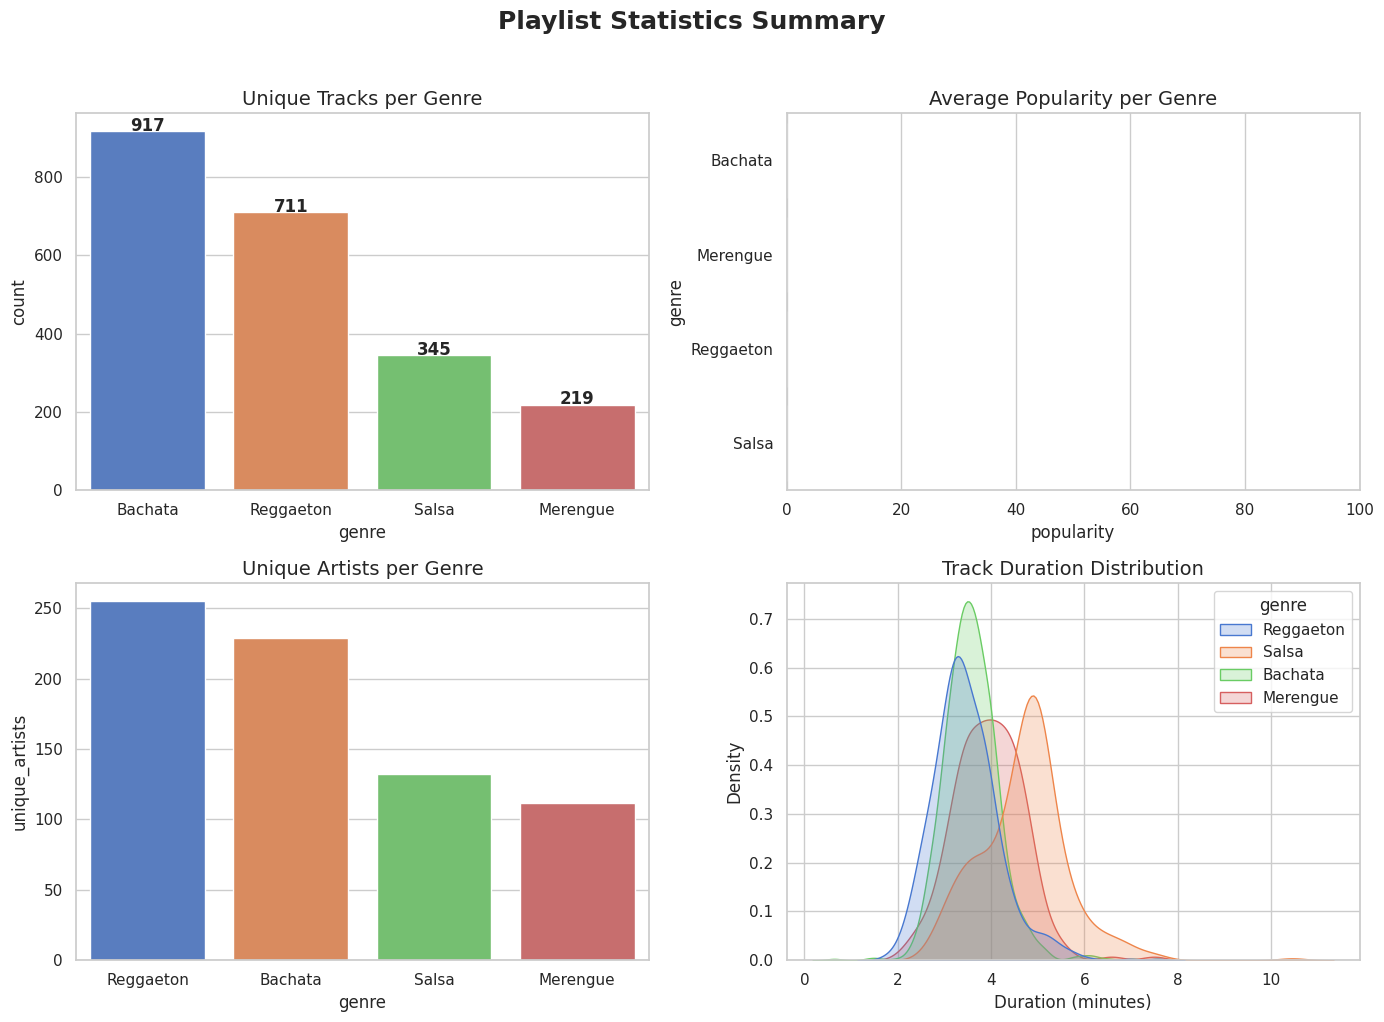

💾 Chart saved → playlist_stats.png


In [8]:
if 'df' in dir() and not df.empty:
    has_extras = {'popularity', 'duration_min'}.issubset(df.columns)
    sns.set_theme(style='whitegrid', palette='muted')

    ncols = 2 if has_extras else 1
    nrows = 2 if has_extras else 1
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 10))
    fig.suptitle('Playlist Statistics Summary', fontsize=18, fontweight='bold', y=1.02)

    # Handle single axis case
    axes_flat = axes.flatten() if has_extras else [axes]
    ax_idx = 0

    # 1. Unique tracks per genre
    counts = df['genre'].value_counts().reset_index()
    counts.columns = ['genre', 'count']
    sns.barplot(data=counts, x='genre', y='count', ax=axes_flat[ax_idx], hue='genre', legend=False)
    axes_flat[ax_idx].set_title('Unique Tracks per Genre', fontsize=14)
    for i, v in enumerate(counts['count']):
        axes_flat[ax_idx].text(i, v + 0.5, str(v), ha='center', fontweight='bold')
    ax_idx += 1

    if has_extras:
        # 2. Average popularity per genre
        pop = df.groupby('genre')['popularity'].mean().sort_values(ascending=False).reset_index()
        sns.barplot(data=pop, x='popularity', y='genre', ax=axes_flat[ax_idx], hue='genre', legend=False)
        axes_flat[ax_idx].set_title('Average Popularity per Genre', fontsize=14)
        axes_flat[ax_idx].set_xlim(0, 100)
        ax_idx += 1

        # 3. Unique artists per genre
        art = df.groupby('genre')['artist'].nunique().sort_values(ascending=False).reset_index()
        art.columns = ['genre', 'unique_artists']
        sns.barplot(data=art, x='genre', y='unique_artists', ax=axes_flat[ax_idx], hue='genre', legend=False)
        axes_flat[ax_idx].set_title('Unique Artists per Genre', fontsize=14)
        ax_idx += 1

        # 4. Duration distribution
        sns.kdeplot(data=df, x='duration_min', hue='genre', fill=True, common_norm=False, ax=axes_flat[ax_idx])
        axes_flat[ax_idx].set_title('Track Duration Distribution', fontsize=14)
        axes_flat[ax_idx].set_xlabel('Duration (minutes)')

    plt.tight_layout()
    plt.savefig('playlist_stats.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("💾 Chart saved → playlist_stats.png")
    if not has_extras:
        print("ℹ️  Re-run the extraction cell to also see popularity & duration charts.")
else:
    print("⚠️  Run the extraction cell first (Step 4).")

## 9. Top 10 Artists per Genre

/tmp/ipykernel_25302/2531843847.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, ax=ax, palette='magma')
/tmp/ipykernel_25302/2531843847.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, ax=ax, palette='magma')
/tmp/ipykernel_25302/2531843847.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, ax=ax, palette='magma')
/tmp/ipykernel_25302/2531843847.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0.

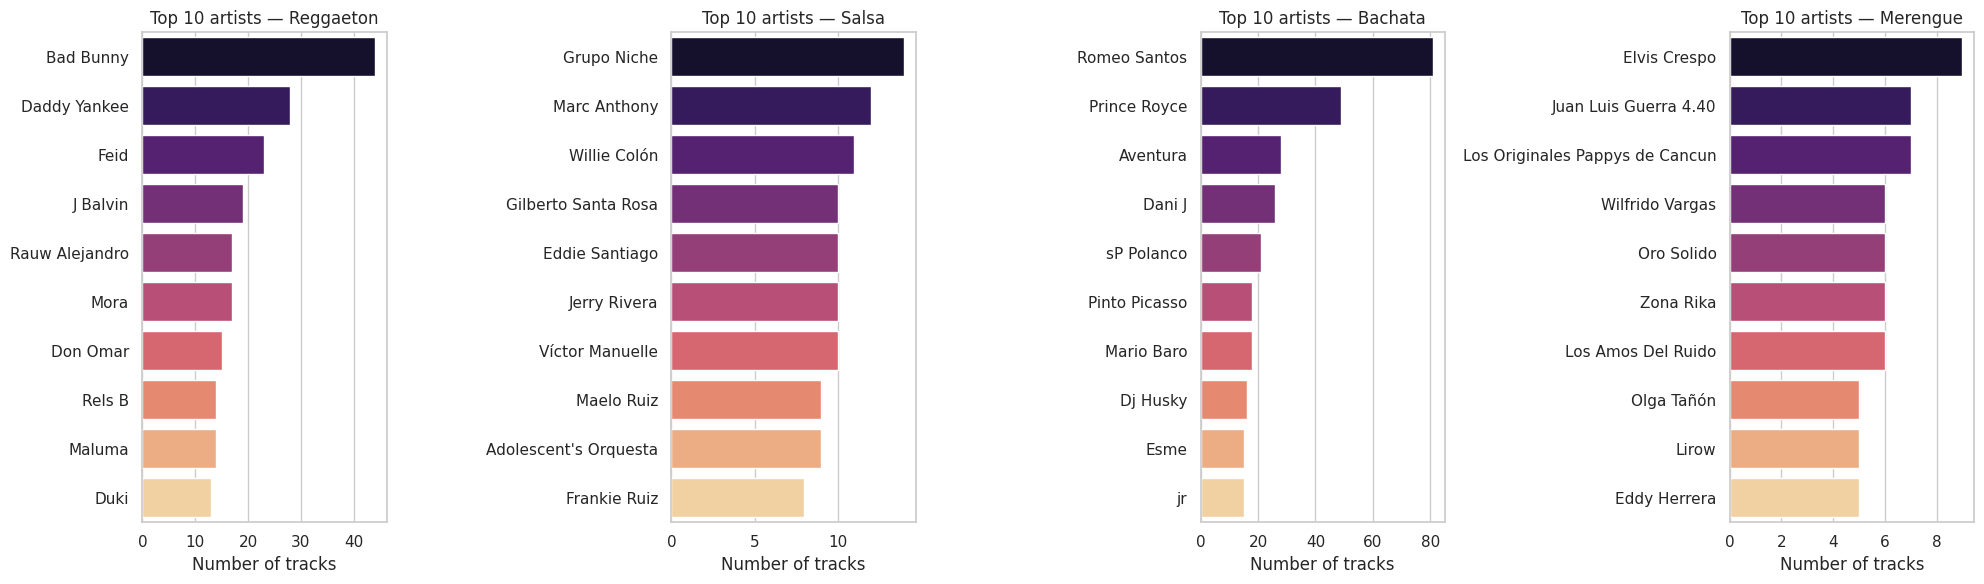

💾 Chart saved → top_artists_by_genre.png


In [9]:
if 'df' in dir() and not df.empty:
    genres = df['genre'].unique()
    fig, axes = plt.subplots(1, len(genres), figsize=(5 * len(genres), 6))
    if len(genres) == 1:
        axes = [axes]

    for ax, genre in zip(axes, genres):
        top = df[df['genre'] == genre]['artist'].value_counts().head(10)
        sns.barplot(x=top.values, y=top.index, ax=ax, palette='magma')
        ax.set_title(f'Top 10 artists — {genre}', fontsize=12)
        ax.set_xlabel('Number of tracks')
        ax.set_ylabel('')

    plt.tight_layout()
    plt.savefig('top_artists_by_genre.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("💾 Chart saved → top_artists_by_genre.png")
else:
    print("⚠️  Run the extraction cell first (Step 4).")
